Appraisal of adaptation measures with trajectories
==================================================

The `StaticAppraiser` evaluates the effect of adaptation measures on risk at several points in time. It extends the `StaticRiskTrajectory` (see the [Trajectories tutorial](climada_trajectories.ipynb)): for each `Snapshot` it computes the risk without adaptation and with each measure of a `MeasureSet`, and reports the averted risk and the cost of each measure. From there, the benefits and costs of the measures can be compared over a period of time.

It is meant to replace the `CostBenefit` class (see the [end-to-end cost-benefit tutorial](climada_engine_CostBenefit.ipynb)); a [summary of the differences](#Migrating-from-CostBenefit) is given at the end of this tutorial.

## Quickstart example

In the following example we use the DEMO data to showcase the basic workflow to use this module.

As usual, a thorough read of this tutorial is highly recommended!

,snap_id,date,group,measure,metric,unit,risk,reference risk,averted risk,measure implementation cost
0,0,2018-01-01,All,no_measure,aai,USD,2.888955e+08,2.888955e+08,0.000000e+00,0.000000e+00
1,1,2018-01-01,All,Measure A,aai,USD,9.531504e+07,2.888955e+08,1.935804e+08,2.000000e+09
2,2,2018-01-01,All,Measure B,aai,USD,2.600059e+08,2.888955e+08,2.888955e+07,2.200000e+08
0,3,2050-01-01,All,no_measure,aai,USD,6.933491e+08,6.933491e+08,0.000000e+00,0.000000e+00
1,4,2050-01-01,All,Measure A,aai,USD,2.287561e+08,6.933491e+08,4.645930e+08,2.000000e+09
2,5,2050-01-01,All,Measure B,aai,USD,6.240142e+08,6.933491e+08,6.933491e+07,2.200000e+08


,benefit,cost,income,net,benefit_cost_ratio
measure,,,,,
Measure A,1.099537e+10,2.000000e+09,0.0,2.000000e+09,5.497684
Measure B,1.640926e+09,2.840000e+08,0.0,2.840000e+08,5.777909


<Axes: ylabel='Benefit / cost'>

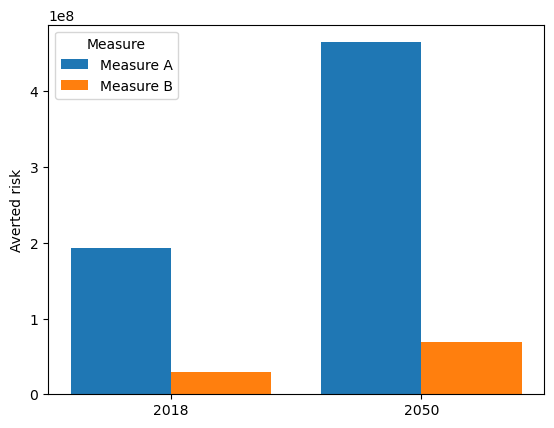

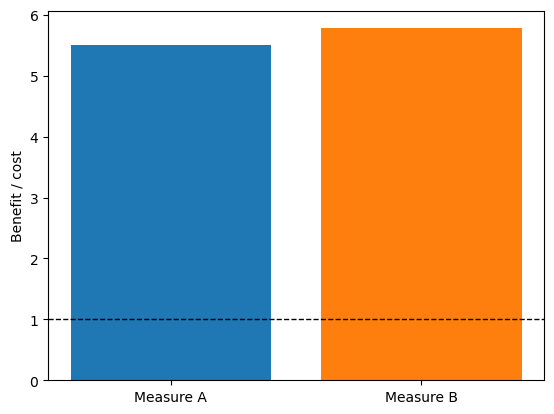

In [46]:
import warnings

from climada.entity import Entity, ImpactFuncSet, ImpfTropCyclone
from climada.entity.measures import Measure, MeasureSet
from climada.entity.measures.measure_config import MeasureConfig
from climada.hazard import Hazard
from climada.engine.option_appraisal import plotting as aplt
from climada.trajectories.snapshot import Snapshot
from climada.engine.option_appraisal.appraiser import StaticAppraiser
from climada.util import HAZ_DEMO_H5
from climada.util.constants import ENT_DEMO_FUTURE, ENT_DEMO_TODAY

warnings.simplefilter("ignore")

# Load exposure
exp_present = Entity.from_excel(ENT_DEMO_TODAY).exposures
exp_future = Entity.from_excel(ENT_DEMO_FUTURE).exposures

# Load Hazard
haz_present = Hazard.from_hdf5(HAZ_DEMO_H5)
haz_future = Hazard.from_hdf5(HAZ_DEMO_H5)
haz_future.frequency *= 1.2

# Load impact function set
impf_set = ImpactFuncSet([ImpfTropCyclone.from_emanuel_usa()])

# Create the snapshots
snap1 = Snapshot(
    exposure=exp_present, hazard=haz_present, impfset=impf_set, date="2018"
)
snap2 = Snapshot(exposure=exp_future, hazard=haz_future, impfset=impf_set, date="2050")

# Define two (made-up) measures
measure_set = MeasureSet(
    [
        Measure.from_config(
            MeasureConfig.from_dict(
                {
                    "name": "Measure A",
                    "haz_type": "TC",
                    "haz_int_add": -5.0,  # wind speeds reduced by 5 m/s
                    "init_cost": 2_000_000_000,
                }
            )
        ),
        Measure.from_config(
            MeasureConfig.from_dict(
                {
                    "name": "Measure B",
                    "haz_type": "TC",
                    "impf_paa_add": -0.1,  # 10% fewer assets affected
                    "init_cost": 220_000_000,
                    "periodic_cost": 2_000_000,  # yearly maintenance
                }
            )
        ),
    ]
)

# Create the appraiser
appraiser = StaticAppraiser([snap1, snap2], measure_set=measure_set)

# Observe the results: risk, reference risk, averted risk and cost of each measure
display(appraiser.aai_metrics())
aplt.plot_averted_risk(appraiser.aai_metrics(), group="All")

# Cost-benefit of each measure over a period of time
cost_benefit = appraiser.cost_benefit_over_period((2018, 2050))
display(cost_benefit)
aplt.plot_benefit_cost(cost_benefit)

## Important disclaimers

### Static means static

The `StaticAppraiser` evaluates risk at the dates of the snapshots only. As for the `StaticRiskTrajectory`, think of a `Snapshot` as a representation of risk **at, or around**, its date.

To compute a cost-benefit over a period, we use that idea literally: each year of the period is attributed to the nearest snapshot (the boundary between two snapshots is their midpoint), whose averted risk is taken as representative of that year. The result is a step function, not an interpolation. If your snapshots are far apart, the cost-benefit will be correspondingly coarse. An interpolated appraiser, bringing the evolution of risk between snapshots, will be added later.

### Memory and computation requirements

Each measure is applied to each snapshot, and risk is computed for each result. The computation and memory requirements are thus **multiplied** by `len(measure_set) + 1` compared to the same `StaticRiskTrajectory`. We encourage you to first try on small examples before running big computations.

### Costs and discounting

- The cost reported alongside the risk metrics (`measure_impl_cost`) is the initial cost of the measure only. Periodic costs, incomes and their growth are only accounted for in the cost-benefit over a period.
- Measures are assumed to be implemented at the start of the period, and effective from then on.
- Costs follow the cash flows of the measure (see its `CostIncome`), at its own frequency. For a period only partly covering a year, the benefit is weighted by the fraction of the year covered, but not the costs.
- Costs and incomes are reported as positive amounts, the net cost being the cost minus the income.

## Using the `appraiser` module

The `StaticAppraiser` aims at facilitating answering questions such as:

- How much risk does each measure avert, at each date, for different risk metrics (average annual impact, return periods, per location, per exposure group)?
- How do these effects change with changing hazard, exposure and vulnerability?
- Over a given period, do the benefits of a measure outweigh its costs? When does it pay back?
- How sensitive are these conclusions to the period and the discount rate?

It combines three ingredients:

- `Snapshot` objects, describing risk at different dates (see the Trajectories tutorial),
- a `MeasureSet`, containing the measures to appraise,
- optionally, `DiscRates`, to express risk in net present value.

## Adaptation measures

Measures are described in detail in the [measure configuration tutorial](climada_measure_config.ipynb). In short, a measure is easily defined with a `MeasureConfig`, itself most conveniently defined from a dictionary, and then turned into a `Measure`.

In the following we reuse the two (made-up) measures of the former cost-benefit tutorial: one that reduces wind speeds by 5 m/s, and one that makes 10% fewer assets be affected. We also add yearly maintenance costs to the second one.

For the former `Measure` attributes used in this tutorial, the equivalents are:

| Former `Measure` | `MeasureConfig` |
| :--- | :--- |
| `cost` | `init_cost` (plus `periodic_cost`, `periodic_income`, growth rates, ...) |
| `hazard_inten_imp=(a, b)` | `haz_int_mult=a`, `haz_int_add=b` |
| `mdd_impact=(a, b)` | `impf_mdd_mult=a`, `impf_mdd_add=b` |
| `paa_impact=(a, b)` | `impf_paa_mult=a`, `impf_paa_add=b` |
| `imp_fun_map="1to3"` | `reassign_impf_id={"TC": {1: 3}}` |

In [3]:
from climada.entity.measures import Measure, MeasureSet
from climada.entity.measures.measure_config import MeasureConfig

measure_a = Measure.from_config(
    MeasureConfig.from_dict(
        {
            "name": "Measure A",
            "haz_type": "TC",
            "color_rgb": (0.8, 0.1, 0.1),
            "haz_int_add": -5.0,  # wind speeds reduced by 5 m/s
            "init_cost": 2_000_000_000,
        }
    )
)
measure_b = Measure.from_config(
    MeasureConfig.from_dict(
        {
            "name": "Measure B",
            "haz_type": "TC",
            "color_rgb": (0.1, 0.1, 0.8),
            "impf_paa_add": -0.1,  # 10% fewer assets affected
            "init_cost": 220_000_000,
            "periodic_cost": 2_000_000,  # yearly maintenance
        }
    )
)
measure_set = MeasureSet([measure_a, measure_b])

**Note.** The risk transfer options of the former `Measure` (`risk_transf_attach`, `risk_transf_cover`) have no equivalent in the appraiser.

## `Snapshot`s: risk with and without adaptation

The appraiser takes a list of snapshots **without** measures: it is in charge of applying the measures to each of them. We use the same data as in the Trajectories tutorial (Haiti, tropical cyclones and LitPop exposure), for the present (2018) and the future (2040).

In [4]:
import copy

from climada.entity import ImpactFuncSet, ImpfTropCyclone
from climada.trajectories.snapshot import Snapshot
from climada.util.api_client import Client

client = Client()
present_year, future_year = 2018, 2040

# Present
exp_present = client.get_litpop(country="Haiti")
haz_present = client.get_hazard(
    "tropical_cyclone",
    properties={
        "country_name": "Haiti",
        "climate_scenario": "historical",
        "nb_synth_tracks": "10",
    },
)
impf_set = ImpactFuncSet([ImpfTropCyclone.from_emanuel_usa()])
exp_present.gdf.rename(columns={"impf_": "impf_TC"}, inplace=True)
exp_present.gdf["impf_TC"] = 1

# Future: 2% yearly economic growth and a warmer climate
exp_future = copy.deepcopy(exp_present)
exp_future.ref_year = future_year
n_years = exp_future.ref_year - exp_present.ref_year + 1
exp_future.gdf["value"] = exp_future.gdf["value"] * 1.02**n_years
haz_future = client.get_hazard(
    "tropical_cyclone",
    properties={
        "country_name": "Haiti",
        "climate_scenario": "rcp60",
        "ref_year": str(future_year),
        "nb_synth_tracks": "10",
    },
)

snap1 = Snapshot(
    exposure=exp_present, hazard=haz_present, impfset=impf_set, date=str(present_year)
)
snap2 = Snapshot(
    exposure=exp_future, hazard=haz_future, impfset=impf_set, date=str(future_year)
)

## Appraising the measures: `StaticAppraiser`

The appraiser is instantiated from the list of snapshots and the `MeasureSet`:

In [5]:
from climada.engine.option_appraisal.appraiser import StaticAppraiser

appraiser = StaticAppraiser([snap1, snap2], measure_set=measure_set)

The other optional arguments are:

- `return_periods`: the return periods to compute (as for trajectories),
- `risk_disc_rates` and `cost_disc_rates`: discount rates for the risk and the costs (see [below](#Discount-rates)),
- `impact_computation_strategy`: the way impacts are computed (as for trajectories),
- `measure_kwargs` and `enforce_baseline_copy`: see [Advanced usage](#Advanced-usage).

As for trajectories, computations are only run and cached when needed (see [Results caching](#Results-caching)).

### Tidy format

The results use the same tidy format as the trajectories (see the Trajectories tutorial), with some additional columns:

| column | description |
| :--- | :--- |
| `measure` | The measure applied. Rows without adaptation are labelled `no_measure` (`NO_MEASURE_VALUE`). |
| `risk` | The risk **with** the measure applied. |
| `reference risk` | The risk without measure, for the same group, metric and date. |
| `averted risk` | `reference risk` minus `risk`. |
| `measure implementation cost` | The initial cost of the measure. |

Metrics are accessed as for the trajectories: `per_date_risk_metrics()`, `aai_metrics()`, `aai_per_group_metrics()`, `return_periods_metrics()` and `eai_metrics()`. The averted risk is available for **all** of them.

In [6]:
appraiser.aai_metrics()

,snap_id,date,group,measure,metric,unit,risk,reference risk,averted risk,measure implementation cost
0,0,2018-01-01,All,no_measure,aai,USD,1.840432e+08,1.840432e+08,0.000000e+00,0.000000e+00
1,1,2018-01-01,All,Measure A,aai,USD,1.075681e+08,1.840432e+08,7.647511e+07,2.000000e+09
2,2,2018-01-01,All,Measure B,aai,USD,1.656389e+08,1.840432e+08,1.840432e+07,2.200000e+08
0,3,2040-01-01,All,no_measure,aai,USD,3.217250e+08,3.217250e+08,0.000000e+00,0.000000e+00
1,4,2040-01-01,All,Measure A,aai,USD,1.917522e+08,3.217250e+08,1.299728e+08,2.000000e+09
2,5,2040-01-01,All,Measure B,aai,USD,2.895525e+08,3.217250e+08,3.217250e+07,2.200000e+08


Being tidy, the results are easily filtered with `pandas`. For instance, to compare the averted risk and the cost of each measure at each date:

In [7]:
from climada.engine.option_appraisal.constants import (
    AVERTED_RISK_NAME,
    MEASURE_IMPL_COST_NAME,
    REFERENCE_RISK_NAME,
)
from climada.trajectories.constants import (
    DATE_COL_NAME,
    MEASURE_COL_NAME,
    NO_MEASURE_VALUE,
    RISK_COL_NAME,
)

aai = appraiser.aai_metrics()
aai[aai[MEASURE_COL_NAME] != NO_MEASURE_VALUE][
    [
        MEASURE_COL_NAME,
        DATE_COL_NAME,
        REFERENCE_RISK_NAME,
        RISK_COL_NAME,
        AVERTED_RISK_NAME,
        MEASURE_IMPL_COST_NAME,
    ]
].sort_values([MEASURE_COL_NAME, DATE_COL_NAME])

,measure,date,reference risk,risk,averted risk,measure implementation cost
1,Measure A,2018-01-01,1.840432e+08,1.075681e+08,7.647511e+07,2.000000e+09
1,Measure A,2040-01-01,3.217250e+08,1.917522e+08,1.299728e+08,2.000000e+09
2,Measure B,2018-01-01,1.840432e+08,1.656389e+08,1.840432e+07,2.200000e+08
2,Measure B,2040-01-01,3.217250e+08,2.895525e+08,3.217250e+07,2.200000e+08


**Note.** The averted risk is an *annual* quantity (for the `aai`), while the implementation cost is a one-off. Dividing one by the other is not a cost-benefit ratio. See [Cost-benefit over a period](#Cost-benefit-over-a-period) for that.

## Visualising the effect of the measures

The `appraiser_plots` module provides ready-made plots for the results. All functions take the DataFrames returned by the appraiser, accept an existing `ax` (or `axes`) to draw on, and return the matplotlib objects drawn.

Here, `group="All"` selects the aggregate over all exposure points (see [Exposure sub groups](#Exposure-sub-groups)).

#### Averted risk

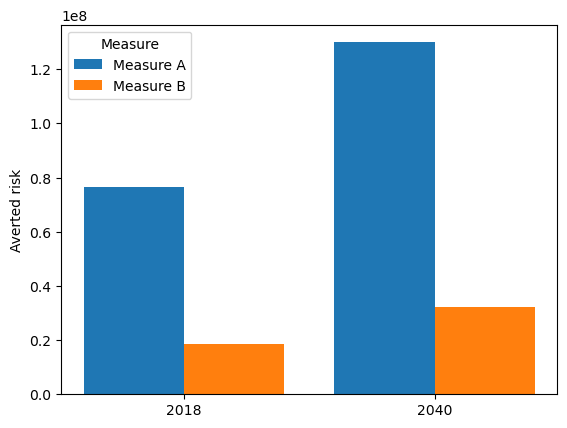

In [8]:
from climada.engine.option_appraisal import plotting as aplt

aplt.plot_averted_risk(appraiser.aai_metrics(), group="All");

#### Residual and averted risk

For each date, the gray bar is the risk without measure. For each measure, the solid bar is the residual risk, and the hatched bar the averted risk, so that the top of the stack matches the gray bar.

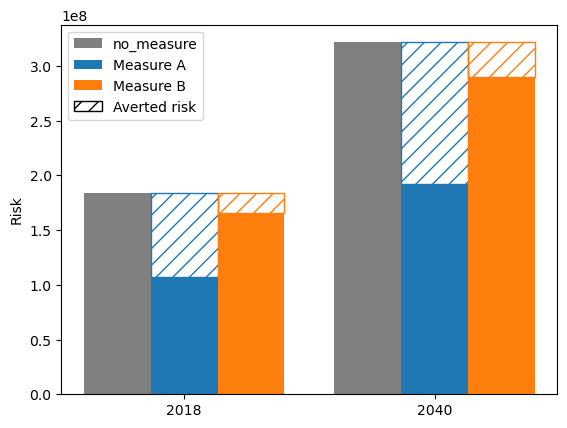

In [9]:
aplt.plot_risk_with_measures(appraiser.aai_metrics(), group="All");

#### Impact exceedance curves

The effect of the measures at different return periods, for each date. The shaded areas are the averted impacts. Note that only the return periods defined at instantiation are available (see [Non-default return periods](#Non-default-return-periods)).

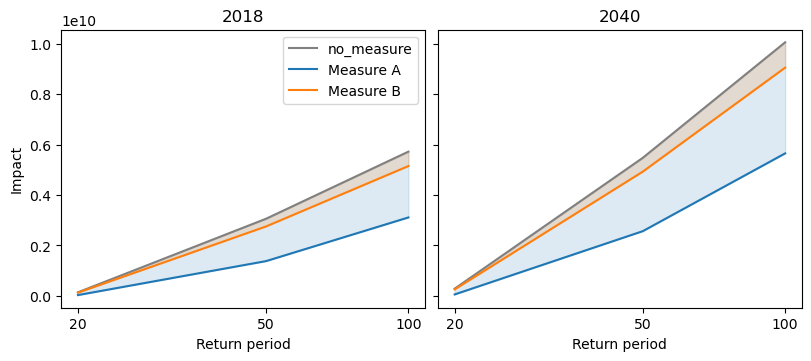

In [10]:
aplt.plot_exceedance_curves(appraiser.return_periods_metrics(), group="All");

#### Averted risk against cost

A quick way to rank the measures at a given date. The dashed lines are lines of constant payback time (implementation cost divided by averted annual risk).

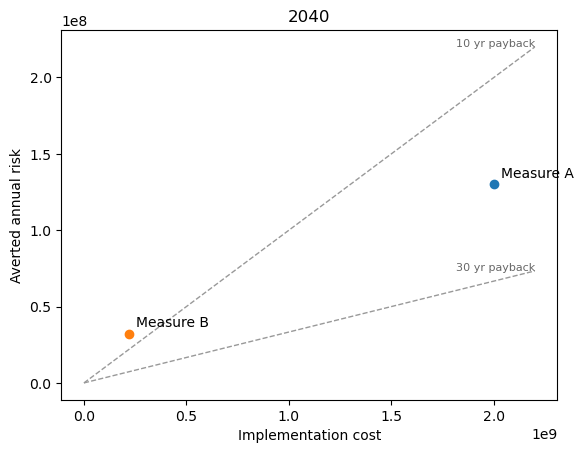

In [11]:
aplt.plot_averted_vs_cost(appraiser.aai_metrics(), group="All", payback_years=(10, 30));

## Cost-benefit over a period

The `cost_benefit_over_period()` method summarizes the benefits and costs of each measure over a period of time. Each year $y$ of the period is attributed to the nearest snapshot $s(y)$ (see [Disclaimers](#Static-means-static)), and:

$$\text{benefit} = \sum_{y \in \text{period}} w_y \, D(y) \, \text{averted risk}_{s(y)}$$

where $w_y$ is the fraction of year $y$ covered by the period (1 except for incomplete years), and $D(y)$ the discount factor (1 without discount rates, see [Discount rates](#Discount-rates)). The net cost is the sum over the period of the cash flows of the measure (initial and periodic costs, minus incomes, as defined in its `CostIncome`), discounted as well if `cost_disc_rates` are set. Then:

$$\text{benefit-cost ratio} = \frac{\text{benefit}}{\text{net cost}}$$

**Note** that this is the *inverse* of the cost/benefit ratio defined in the former cost-benefit tutorial: larger is better, and measures are worth it (on financial grounds alone) above 1.

The period is given by its first and last years (both included):

In [42]:
cost_benefit = appraiser.cost_benefit_over_period((present_year, future_year))
cost_benefit

,benefit,cost,income,net,benefit_cost_ratio
measure,,,,,
Measure A,2.400900e+09,2.000000e+09,0.0,2.000000e+09,1.200450
Measure B,5.885176e+08,2.640000e+08,0.0,2.640000e+08,2.229233


The period can also be given as any pair of dates understood by `pandas.Timestamp`, in which case the end is excluded (see [Non-yearly periods](#Non-yearly-periods)).

#### Benefit-cost ratio

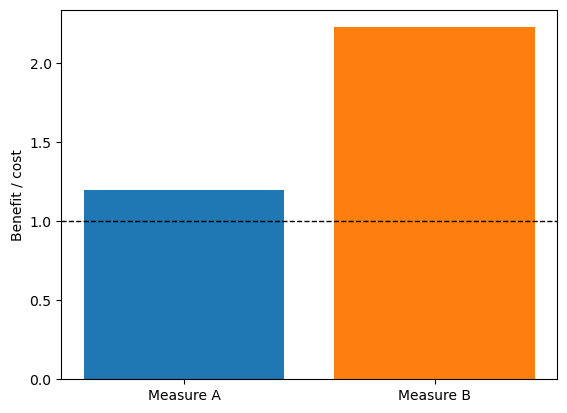

In [43]:
aplt.plot_benefit_cost(cost_benefit);

#### Cost-benefit area plot

The benefit-cost ratio against the cumulated benefit: the area of each bar is the benefit of the measure, and a measure going above 1 on the y-axis has a benefit larger than its cost. This replaces the former `CostBenefit.plot_cost_benefit`.

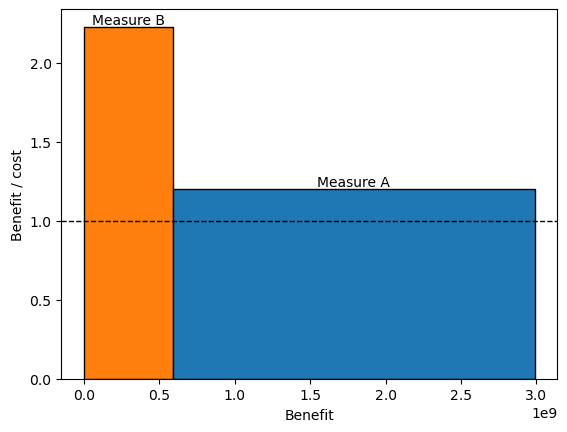

In [44]:
aplt.plot_cost_benefit_area(cost_benefit);

#### Payback time

`cumulative_net_benefit()` gives the cumulated benefit minus the cumulated net cost over the period. A measure pays back when its curve crosses zero.

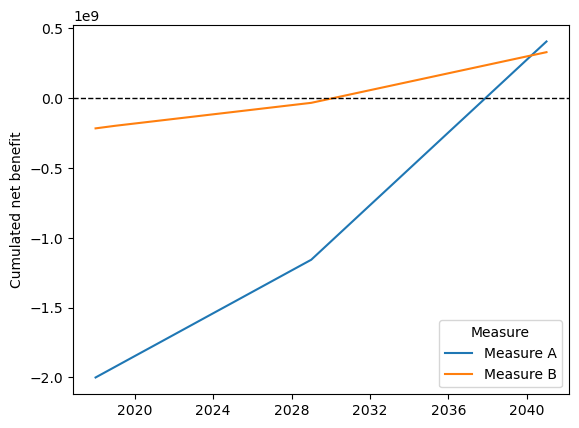

In [45]:
cumulative = appraiser.cumulative_net_benefit((present_year, future_year))
aplt.plot_cumulative_net_benefit(cumulative);

### Discount rates

As for trajectories, discount rates can be given as `DiscRates` objects, for the risk (`risk_disc_rates`) and for the costs (`cost_disc_rates`), either at instantiation or directly in `cost_benefit_over_period()`, where they override those of the appraiser.

The two are used differently:

- At instantiation, `risk_disc_rates` converts all risk values (and thus the averted risk) of the tidy results to net present values **at the date of their snapshot**, taking the first snapshot as baseline (no discounting). This is the right way to look at the metrics at each date.
- In the cost-benefit, the benefit of **each year** of the period is discounted to the **start of the period**. The net present values of the tidy results are undone beforehand, so that discounting is applied once, with the right factor for each year. Costs and incomes are discounted the same way with `cost_disc_rates`.

The discount rates need to cover all the years of the period (after its first one), or an error is raised.

Reusing the setup of the former tutorial, with the often used 1.4% Stern discount rate:

In [15]:
import numpy as np

from climada.entity import DiscRates

year_range = np.arange(present_year, future_year + 1)
discount_zero = DiscRates(year_range, np.zeros(year_range.size))
discount_stern = DiscRates(year_range, np.full(year_range.size, 0.014))

In [16]:
appraiser = StaticAppraiser([snap1, snap2], measure_set=measure_set)
appraiser_stern = StaticAppraiser(
    [snap1, snap2],
    measure_set=measure_set,
    risk_disc_rates=discount_stern,
    cost_disc_rates=discount_stern,
)

In [25]:
appraiser.cost_benefit_over_period((2018, 2040))
appraiser_stern.cost_benefit_over_period((2018, 2040))

,benefit,cost,income,net,benefit_cost_ratio
measure,,,,,
Measure A,2.026882e+09,2.000000e+09,0.0,2.000000e+09,1.013441
Measure B,4.963190e+08,2.576447e+08,0.0,2.576447e+08,1.926370


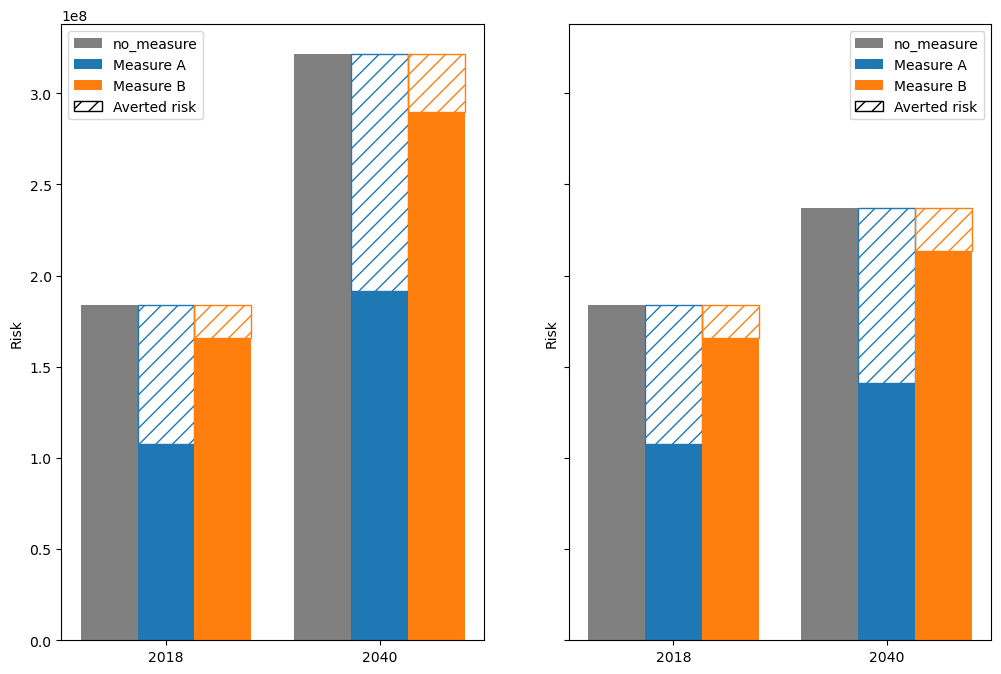

In [32]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 8), sharey=True)

aplt.plot_risk_with_measures(appraiser.aai_metrics(), group="All", ax=axs[0])
aplt.plot_risk_with_measures(appraiser_stern.aai_metrics(), group="All", ax=axs[1]);

In [ ]:
import pandas as pd

cost_benefit = appraiser.cost_benefit_over_period((present_year, future_year))

cost_benefit_stern = appraiser_stern.cost_benefit_over_period(
    (present_year, future_year),
    risk_disc_rates=discount_stern,
    cost_disc_rates=discount_stern,
)

pd.concat([cost_benefit, cost_benefit_stern], keys=["no_discount", "stern"])

In [32]:
appraiser.aai_metrics()

,snap_id,date,group,measure,metric,unit,risk,reference risk,averted risk,measure implementation cost
0,0,2018-01-01,All,no_measure,aai,USD,1.840432e+08,1.840432e+08,0.000000e+00,0.000000e+00
1,1,2018-01-01,All,Measure A,aai,USD,1.075681e+08,1.840432e+08,7.647511e+07,2.000000e+09
2,2,2018-01-01,All,Measure B,aai,USD,1.656389e+08,1.840432e+08,1.840432e+07,2.200000e+08
0,3,2040-01-01,All,no_measure,aai,USD,3.217250e+08,3.217250e+08,0.000000e+00,0.000000e+00
1,4,2040-01-01,All,Measure A,aai,USD,1.917522e+08,3.217250e+08,1.299728e+08,2.000000e+09
2,5,2040-01-01,All,Measure B,aai,USD,2.895525e+08,3.217250e+08,3.217250e+07,2.200000e+08


In [38]:
appraiser._yearly_benefits(
    pd.Timestamp(year=2018, month=1, day=1),
    pd.Timestamp(year=2041, month=1, day=1),
    None,
)

measure,Measure A,Measure B
2018-01-01,7.647511e+07,1.840432e+07
2019-01-01,7.647511e+07,1.840432e+07
2020-01-01,7.647511e+07,1.840432e+07
2021-01-01,7.647511e+07,1.840432e+07
2022-01-01,7.647511e+07,1.840432e+07
2023-01-01,7.647511e+07,1.840432e+07
2024-01-01,7.647511e+07,1.840432e+07
2025-01-01,7.647511e+07,1.840432e+07
2026-01-01,7.647511e+07,1.840432e+07
2027-01-01,7.647511e+07,1.840432e+07


In [35]:
appraiser_stern.aai_metrics()

,snap_id,date,group,measure,metric,unit,risk,reference risk,averted risk,measure implementation cost
0,0,2018-01-01,All,no_measure,aai,USD,1.840432e+08,1.840432e+08,0.000000e+00,0.000000e+00
1,1,2018-01-01,All,Measure A,aai,USD,1.075681e+08,1.840432e+08,7.647511e+07,2.000000e+09
2,2,2018-01-01,All,Measure B,aai,USD,1.656389e+08,1.840432e+08,1.840432e+07,2.200000e+08
0,3,2040-01-01,All,no_measure,aai,USD,2.369462e+08,2.369462e+08,0.000000e+00,0.000000e+00
1,4,2040-01-01,All,Measure A,aai,USD,1.412230e+08,2.369462e+08,9.572328e+07,2.000000e+09
2,5,2040-01-01,All,Measure B,aai,USD,2.132516e+08,2.369462e+08,2.369462e+07,2.200000e+08


In [39]:
appraiser_stern._yearly_benefits(
    pd.Timestamp(year=2018, month=1, day=1),
    pd.Timestamp(year=2041, month=1, day=1),
    None,
)

measure,Measure A,Measure B
2018-01-01,7.647511e+07,1.840432e+07
2019-01-01,7.647511e+07,1.840432e+07
2020-01-01,7.647511e+07,1.840432e+07
2021-01-01,7.647511e+07,1.840432e+07
2022-01-01,7.647511e+07,1.840432e+07
2023-01-01,7.647511e+07,1.840432e+07
2024-01-01,7.647511e+07,1.840432e+07
2025-01-01,7.647511e+07,1.840432e+07
2026-01-01,7.647511e+07,1.840432e+07
2027-01-01,7.647511e+07,1.840432e+07


The benefits shrink since the future averted risk is worth less, and so do the periodic costs, which is why we discount both here. The initial cost, incurred at the start of the period, is not affected.

As recommended in the former tutorial, check how sensitive your conclusions are to these choices:

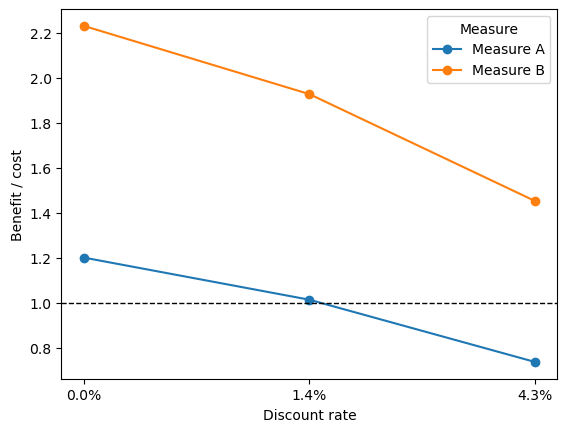

In [40]:
discount_nordhaus = DiscRates(year_range, np.full(year_range.size, 0.043))

results = {
    f"{rate:.1%}": appraiser.cost_benefit_over_period(
        (present_year, future_year), risk_disc_rates=disc, cost_disc_rates=disc
    )
    for rate, disc in [
        (0.0, discount_zero),
        (0.014, discount_stern),
        (0.043, discount_nordhaus),
    ]
}
aplt.plot_ratio_sensitivity(results, xlabel="Discount rate");

**Exercises**:

- Can you design a measure that is a good investment without discounting, and a bad one with a 1.4% (or higher) discount rate?
- Compare the benefit-cost ratios for periods ending in 2030 and 2040. Can you design a measure that is a good investment over the second, but not over the first?

## Advanced usage

In this section we present some more advanced features and use of this module.

### Exposure sub groups

As for trajectories, setting a `group_id` column in the exposure `GeoDataFrame` gives access to the risk of subgroups of exposure points, and the averted risk per group.

In [17]:
exp_present.gdf["group_id"] = (
    exp_present.gdf["value"] > exp_present.gdf["value"].mean()
) * 1
exp_future.gdf["group_id"] = (
    exp_future.gdf["value"] > exp_future.gdf["value"].mean()
) * 1

snap1 = Snapshot(
    exposure=exp_present, hazard=haz_present, impfset=impf_set, date=str(present_year)
)
snap2 = Snapshot(
    exposure=exp_future, hazard=haz_future, impfset=impf_set, date=str(future_year)
)
appraiser = StaticAppraiser([snap1, snap2], measure_set=measure_set)

appraiser.aai_per_group_metrics()

KeyError: "None of ['group'] are in the columns"

In [ ]:
aplt.plot_averted_risk_per_group(
    appraiser.aai_per_group_metrics(), exclude_groups=["All"]
);

**Note.** The implementation cost is repeated on the rows of every group: do not sum it across groups.

### Spatial mapping

`eai_metrics()` gives the expected annual impact at each coordinate, with the corresponding averted risk. The following maps the averted risk of each measure, with a shared color scale:

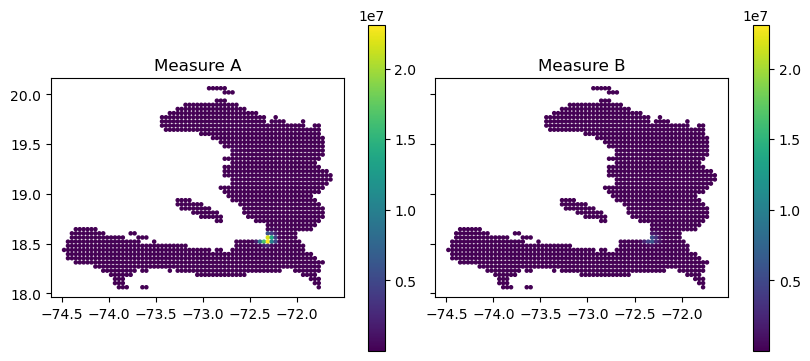

In [18]:
aplt.plot_averted_risk_map(appraiser.eai_metrics(), snap1.exposure.gdf, markersize=5);

Other columns can be mapped with `value_col`, for instance the residual risk (in that case the panel of the baseline is also drawn):

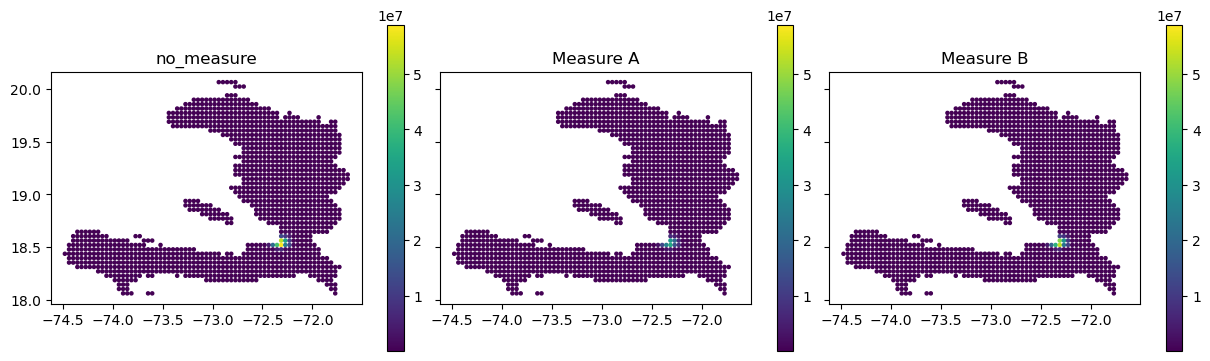

In [19]:
aplt.plot_averted_risk_map(
    appraiser.eai_metrics(), snap1.exposure.gdf, value_col="risk", markersize=5
);

### Non-default return periods

You can change the return periods at initialisation, or via the property `return_periods`, as for trajectories. Note that estimates of impacts for specific return periods are highly dependent on the data you provided. **We cannot check if the event set you provide is fit for computing impacts for a specific return period.**

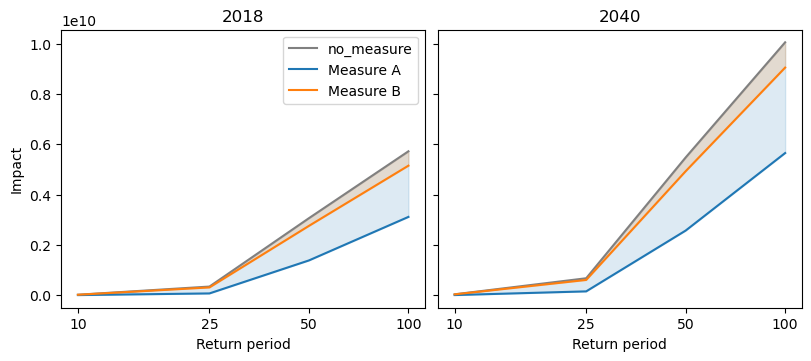

In [20]:
appraiser_rp = StaticAppraiser(
    [snap1, snap2], measure_set=measure_set, return_periods=[10, 25, 50, 100]
)
aplt.plot_exceedance_curves(appraiser_rp.return_periods_metrics(), group="All");

**Note.** The cost-benefit over a period is only defined for the additive metrics: it is based on the average annual impact. Summing impacts of a given return period over years does not give a benefit.

### Higher number of snapshots

You can of course use more than two snapshots. Each year of the period is then attributed to the nearest one. Below, we add a snapshot in 2030, with growth in exposure but the present hazard:

In [21]:
exp_mid = copy.deepcopy(exp_present)
exp_mid.ref_year = 2030
exp_mid.gdf["value"] = exp_present.gdf["value"] * 1.02 ** (2030 - present_year + 1)
snap_mid = Snapshot(exposure=exp_mid, hazard=haz_present, impfset=impf_set, date="2030")

appraiser_3 = StaticAppraiser([snap1, snap_mid, snap2], measure_set=measure_set)
appraiser_3.cost_benefit_over_period((present_year, future_year))

,benefit,cost,income,net_cost,benefit_cost_ratio
measure,,,,,
Measure A,2.326904e+09,2.000000e+09,0.0,2.000000e+09,1.163452
Measure B,5.653485e+08,2.640000e+08,0.0,2.640000e+08,2.141471


A period extending beyond the first or last snapshot is allowed (the nearest snapshot is used), but a warning is issued: be careful with such extrapolation.

### Non-yearly periods

The period can also be given as dates. In that case the end is excluded, and years only partly covered count for the corresponding fraction of the averted risk:

In [22]:
appraiser.cost_benefit_over_period(("2020-07-01", "2030-07-01"))

,benefit,cost,income,net_cost,benefit_cost_ratio
measure,,,,,
Measure A,8.446725e+08,2.000000e+09,0.0,2.000000e+09,0.422336
Measure B,2.046136e+08,2.400000e+08,0.0,2.400000e+08,0.852557


### Measure-specific options

Some measures need extra arguments when applied to a snapshot. These can be given per measure through `measure_kwargs`, a dictionary mapping measure names to keyword arguments:

```python
appraiser = StaticAppraiser(
    snapshots,
    measure_set=measure_set,
    measure_kwargs={"Measure A": {"<option>": <value>}},
)
```

Measure names are checked at instantiation: giving options for a name that is not in `measure_set` raises a `ValueError`. The options actually used for each (snapshot date, measure) pair are stored in `appraiser.applied_kwargs`.

> **TODO.** Document which options are accepted (what the kwargs specification can contain, and whether it can depend on the snapshot date) with a concrete example (e.g. `exposures_region_id`).

### Baseline copy

By default (`enforce_baseline_copy=True`) the risk components of the baseline are copied before a measure is applied, so that measures cannot alter each other's input. Setting it to `False` saves memory, but only do so if you know that your measures leave the baseline untouched.

The `measure_set` is deep-copied at instantiation, so later changes to your `MeasureSet` do not affect the appraiser.

### Results caching

As for trajectories, computations are lazy and results are cached, which can be deactivated by setting "trajectory_caching" to false in CLIMADA's configuration (see [Configuration](../development/Guide_Configuration.ipynb)). Changing `risk_disc_rates` or `cost_disc_rates` after instantiation resets the cache. The caching can get memory expensive with many measures.

### Custom Impact Computation strategy

The `impact_computation_strategy` argument works as for trajectories (see the Trajectories tutorial), and is used for **all** computations, with and without measures.

## Migrating from CostBenefit

### What is not available (yet)

Most of these are quantities integrated over time, and should come back with the interpolated appraiser.

- The time evolution parameter `imp_time_depen` (the $\alpha_k(t)$ function): years are attributed to the nearest snapshot.
- Total climate risk and residual risk over the period.
- Combining measures (`combine_measures()`).
- Risk transfer (insurance) measures.
- Storage of the `Impact` objects (`save_imp`, `imp_meas_present`, `imp_meas_future`) and of the `ImpactFreqCurve` objects.
- Arbitrary risk functions (`risk_func`): metrics are the ones of the trajectories module.
- The waterfall plots (`plot_waterfall`, `plot_arrow_averted`, `plot_waterfall_accumulated`).

### What is done differently

| `CostBenefit` | `StaticAppraiser` |
| :--- | :--- |
| `calc(haz, entity, haz_future, ent_future, future_year)` | A list of `Snapshot`s with explicit dates. |
| Exactly two time points | Any number of snapshots. |
| Measures from the `Entity` | `measure_set=` argument. |
| Discount rates from the present `Entity` | `risk_disc_rates=` and `cost_disc_rates=`, at instantiation or in the cost-benefit. |
| Measures defined declaratively with `Measure(...)` | `MeasureConfig` and `Measure.from_config()`. |
| `cost` of a measure | `init_cost`, and optionally periodic costs and incomes. |
| Benefit per measure as a dictionary | `averted risk` column, at every date. |
| Cost/benefit ratio (smaller is better) | Benefit/cost ratio (larger is better). |
| `risk_func=risk_rp_100` | `return_periods=[100]` and `return_periods_metrics()`. |
| Printouts | Tidy DataFrames. |
| `plot_cost_benefit`, `plot_event_view` | `plot_cost_benefit_area`, `plot_exceedance_curves`. |

### What is new

- Several snapshots in one run, with dates that are not necessarily years.
- Averted risk for every metric: average annual impact, return periods, exposure subgroups, individual coordinates.
- Measures applied to each snapshot, so that they act on the exposure, hazard and vulnerability of that date.
- Custom impact computation strategies.
- Periodic costs and incomes of the measures in the cost-benefit.
- Separate discount rates for risk and costs.
- Lazy computation, caching and protection of the baseline.
- Payback time, sensitivity and spatial plots.
- Later on: interpolation between snapshots.

## Conclusion

Cost-benefit calculations can be powerful policy tools, but they are as much an art as a science. Describing your adaptation measures well, choosing the period to evaluate them over, describing the changing climate and picking a discount rate will all affect your results and whether a particular measure is worth implementing.

Take the time to explain these choices to yourself and anyone else who wants to understand your calculations. It is also good practice to run sensitivity tests on your results: how much do your conclusions change when you use other plausible setups for the calculation?